# CVAE — Arquitectura B (Provincia-Dia)

Una muestra = un dia de una provincia.
x: vector de 24 dimensiones (perfil horario de una provincia).
c: clima de esa provincia + calendario + indicadores socioeconomicos.

El modelo aprende una regla general: alta poblacion + industria implica alta demanda.
Los indicadores socioeconomicos tienen variacion real entre muestras.

In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from preprocessing_b import run_preprocessing_b
from cvae import CVAE
from train_cvae import train, set_seed
from evaluate_cvae import full_evaluation, generate_scenarios, posterior_prior_gap

SPLITS_DIR  = project_root / 'data' / 'splits'
PROCESSED_DIR = project_root / 'data' / 'processed'
RESULTS_DIR = project_root / 'results' / 'cvae_b'
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


## 1. Preprocessing Architecture B

Construimos el dataset en formato provincia-dia.
El split temporal se hace por fecha — no por provincia.

In [15]:
data_b = run_preprocessing_b(
    processed_dir=PROCESSED_DIR,
    save_dir=SPLITS_DIR,
)

X_train = data_b['X_train']
X_val   = data_b['X_val']
X_test  = data_b['X_test']
C_train = data_b['C_train']
C_val   = data_b['C_val']
C_test  = data_b['C_test']

provinces_test = data_b['provinces_test']
x_scaler_b     = data_b['x_scaler']

print(f'X_train: {X_train.shape}, C_train: {C_train.shape}')
print(f'x_dim={X_train.shape[1]}, c_dim={C_train.shape[1]}')

x_wide:      (2311, 529)
clima:       (50842, 14)
calendario:  (2311, 4)
indicadores: (22, 5)

x_long: (50842, 26)  (50842 province-day samples)
c_long: (50842, 21)

Despues de eliminar dias anomalos: 50776 samples

Split:
  train: 32054 samples (1457 dias × 22 provincias)
  val:   8052 samples
  test:  10670 samples

Shapes finales:
  X_train: (32054, 24), X_val: (8052, 24), X_test: (10670, 24)
  C_train: (32054, 19), C_val: (8052, 19), C_test: (10670, 19)
  x_dim: 24, c_dim: 19

Archivos guardados en c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\provincias\data\splits/ con prefijo 'b_'
X_train: (32054, 24), C_train: (32054, 19)
x_dim=24, c_dim=19


## 2. Definir y entrenar el modelo

In [16]:
CONFIG_B = {
    'lr':            1e-3,
    'batch_size':    512,
    'max_epochs':    300,
    'patience':      40,
    'beta':          0.3,     # ← final: prioriza coverage/diversity sobre MAE puro (ver diagnostico abajo)
    'warmup_epochs': 50,
    'free_bits':     1.0,
    'seed':          42,
    'device':        DEVICE,
}

model_b = CVAE(
    x_dim=X_train.shape[1],
    c_dim=C_train.shape[1],
    hidden_dims=[64, 64],
    latent_dim=4,    # ← de 8 a 4: menos lugar para memorizar x, obliga a apoyarse en c
)
print(model_b)

CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=43, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (mu): Linear(in_features=64, out_features=4, bias=True)
    (logvar): Linear(in_features=64, out_features=4, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=23, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (out): Linear(in_features=64, out_features=24, bias=True)
  )
)


In [17]:
history_b = train(
    model_b,
    X_train, C_train,
    X_val,   C_val,
    config=CONFIG_B,
    save_path=RESULTS_DIR / 'cvae_b_checkpoint.pt',
)

Training on cpu | x_dim=24 | c_dim=19 | latent_dim=4
Train: 32054 samples | Val: 8052 samples
------------------------------------------------------------
Epoch 001 | beta=0.006 | train=0.3923 (r=0.3841 kl=1.3682) | val=0.1045 (r=0.0959 kl=1.4220)
Epoch 010 | beta=0.060 | train=0.0699 (r=0.0093 kl=1.0096) | val=0.0669 (r=0.0062 kl=1.0125)
Epoch 020 | beta=0.120 | train=0.1269 (r=0.0068 kl=1.0013) | val=0.1251 (r=0.0049 kl=1.0020)
Epoch 030 | beta=0.180 | train=0.1860 (r=0.0059 kl=1.0007) | val=0.1843 (r=0.0041 kl=1.0013)
Epoch 040 | beta=0.240 | train=0.2455 (r=0.0054 kl=1.0004) | val=0.2439 (r=0.0037 kl=1.0008)

Early stopping at epoch 43 (best val loss: 0.0335)
Checkpoint guardado en c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\provincias\results\cvae_b\cvae_b_checkpoint.pt


## 3. Curvas de entrenamiento

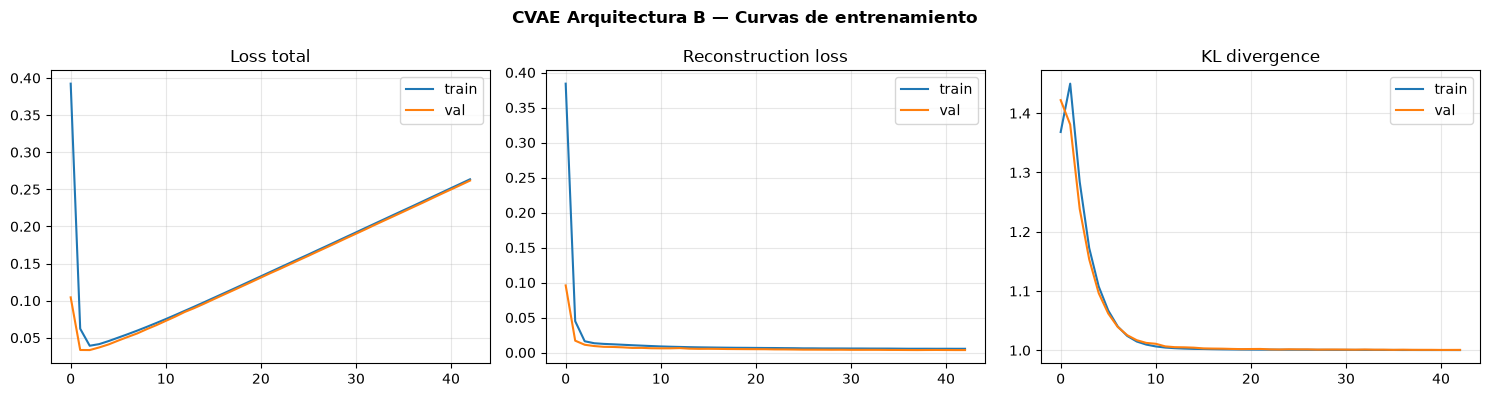

Mejor val loss: 0.0335


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_b['train_loss'], label='train')
axes[0].plot(history_b['val_loss'],   label='val')
axes[0].set_title('Loss total')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_b['train_recon'], label='train')
axes[1].plot(history_b['val_recon'],   label='val')
axes[1].set_title('Reconstruction loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history_b['train_kl'], label='train')
axes[2].plot(history_b['val_kl'],   label='val')
axes[2].set_title('KL divergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('CVAE Arquitectura B — Curvas de entrenamiento', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_training.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mejor val loss: {history_b["best_val_loss"]:.4f}')

### Diagnostico: colapso de condicionamiento

Antes de mirar las metricas de generacion, comparamos dos formas de decodificar en validacion: usando el `mu` real del encoder (que vio el `x` verdadero) contra usando un `z` muestreado del prior `N(0,1)` (lo que realmente pasa al generar escenarios, ya que ahi no hay ningun `x` real disponible, solo `c`).

Si el error con `z` del prior es mucho mas alto que con el `mu` del encoder, el decoder esta dependiendo de informacion filtrada por `z` en vez de aprender de `c` — y por lo tanto la generacion real (la que importa para el proyecto) va a fallar aunque la reconstruccion de entrenamiento se vea bien.

In [19]:
gap_b = posterior_prior_gap(model_b, X_val, C_val, x_scaler_b, device=DEVICE)
print(f'MAE decodificando con mu del encoder (posterior): {gap_b["mae_posterior"]:.1f} MWh')
print(f'MAE decodificando con z del prior (generacion real): {gap_b["mae_prior"]:.1f} MWh')
print(f'Relacion prior/posterior: {gap_b["gap_ratio"]:.1f}x')

MAE decodificando con mu del encoder (posterior): 73.9 MWh
MAE decodificando con z del prior (generacion real): 244.8 MWh
Relacion prior/posterior: 3.3x


### Eleccion final de hiperparametros

Se probaron cuatro configuraciones sobre validacion antes de fijar esta: la version con `beta=1.0` y `free_bits=0.5` da el mejor MAE (68.6 MWh) pero una cobertura P5-P95 baja (66.8%, lejos del ~90% buscado) y una diversidad de escenarios muy chica (0.042). Tambien se probo agregar dropout sobre `c` en el encoder y el decoder para forzar que el modelo dependa menos de la condicion — esa variante empeoro todo (MAE 217.6 MWh, mas del triple, incluso decodificando con el `mu` real del encoder): el dropout no hizo que el modelo aprendiera a usar mejor `z`, simplemente lo volvio mas ruidoso en general.

La configuracion final (`beta=0.3`, `free_bits=1.0`) prioriza cobertura y diversidad de escenarios sobre el MAE puntual: sube la cobertura a ~85% y la diversidad a 0.066, a cambio de un MAE mayor que la version mas agresiva de regularizacion. Es una decision deliberada — para un modelo generativo que se va a evaluar por coverage/sharpness/MMD (no solo por error puntual), preferimos escenarios mejor calibrados aunque el punto central sea menos preciso.

## 4. Evaluacion en validacion

In [20]:
provinces_val = data_b['provinces_val']

metrics_val_b, scenarios_val_b = full_evaluation(
    model_b, X_val, C_val, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_val, architecture='B'
)

print('Metricas en validacion:')
print(f'  MAE global:      {metrics_val_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_val_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_val_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_val_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_val_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_val_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_val_b["mmd"]:.4f}')

Generando 500 escenarios para 8052 muestras...
Calculando metricas...
Metricas en validacion:
  MAE global:      174.7 MWh
  RMSE global:     502.0 MWh
  MAPE energia:    26.02%
  Coverage P5-P95: 86.5%
  Sharpness:       651.2 MWh
  Diversity ratio: 0.127
  MMD:             0.0040


In [21]:
metrics_val_b['per_province']

,provincia,mae_mwh,coverage,sharpness
0,buenos_aires,1697.2,53.4,4276.200195
1,santa_fe,378.0,99.6,2320.100098
2,chubut,325.0,30.9,376.500000
3,cordoba,292.1,99.0,2164.000000
4,mendoza,125.7,97.7,690.099976
5,chaco,121.6,86.1,309.500000
6,san_luis,113.1,59.1,263.799988
7,entre_rios,104.9,99.4,474.899994
8,tucuman,96.3,83.8,268.399994
9,corrientes,91.2,94.0,282.700012


## 5. Visualizacion de escenarios generados

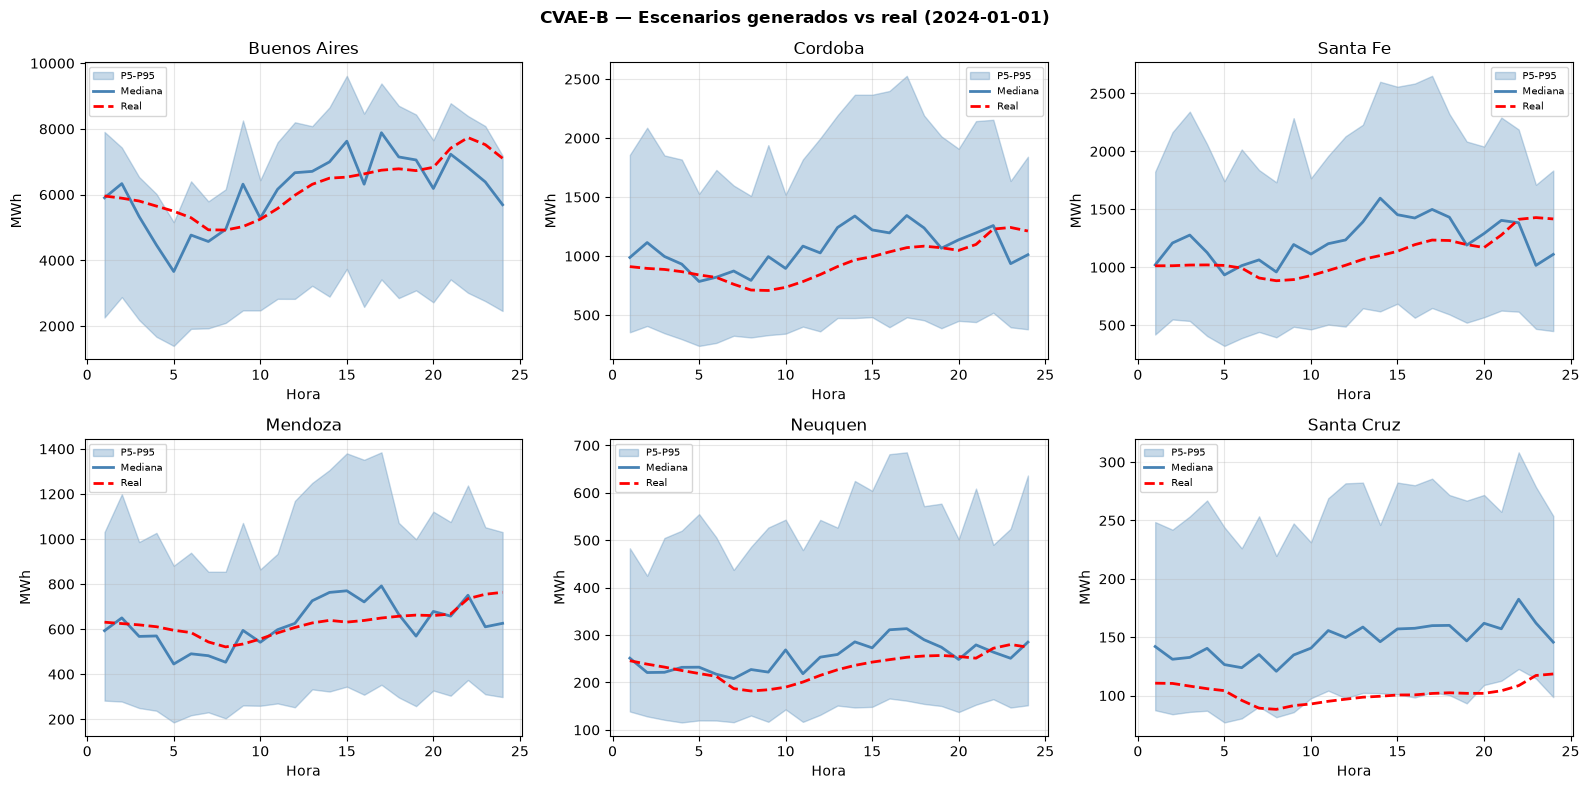

In [22]:
# Visualizar escenarios para 6 provincias en un dia de val
provinces_to_show = ['buenos_aires', 'cordoba', 'santa_fe', 'mendoza', 'neuquen', 'santa_cruz']
PROVINCE_ORDER = [
    'buenos_aires', 'catamarca', 'chaco', 'chubut', 'cordoba',
    'corrientes', 'entre_rios', 'formosa', 'jujuy', 'la_pampa',
    'la_rioja', 'mendoza', 'misiones', 'neuquen', 'rio_negro',
    'salta', 'san_juan', 'san_luis', 'santa_cruz', 'santa_fe',
    'sgo_del_estero', 'tucuman',
]

# En arch B, una fecha tiene 22 filas (una por provincia)
# Tomamos el primer dia del val set
first_date = pd.to_datetime(data_b['dates_val'])[0]
val_dates_ts = pd.to_datetime(data_b['dates_val'])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, prov in zip(axes.flat, provinces_to_show):
    mask = (val_dates_ts == first_date) & (provinces_val == prov)
    if not mask.any():
        continue
    idx = np.where(mask)[0][0]
    real_mwh = x_scaler_b.inverse_transform(X_val[idx:idx+1]).flatten()
    scen_mwh = np.stack([
        x_scaler_b.inverse_transform(scenarios_val_b[idx, s:s+1, :]).flatten()
        for s in range(scenarios_val_b.shape[1])
    ])
    p5  = np.percentile(scen_mwh, 5,  axis=0)
    p50 = np.percentile(scen_mwh, 50, axis=0)
    p95 = np.percentile(scen_mwh, 95, axis=0)
    horas = range(1, 25)
    ax.fill_between(horas, p5, p95, alpha=0.3, color='steelblue', label='P5-P95')
    ax.plot(horas, p50,      color='steelblue', linewidth=2, label='Mediana')
    ax.plot(horas, real_mwh, color='red',       linewidth=2, label='Real', linestyle='--')
    ax.set_title(prov.replace('_', ' ').title())
    ax.set_xlabel('Hora')
    ax.set_ylabel('MWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle(f'CVAE-B — Escenarios generados vs real ({first_date.date()})', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Resultado final en test

In [23]:
metrics_test_b, _ = full_evaluation(
    model_b, X_test, C_test, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_test, architecture='B'
)

print('=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===')
print(f'  MAE global:      {metrics_test_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_test_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_test_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_test_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_test_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_test_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_test_b["mmd"]:.4f}')

Generando 500 escenarios para 10670 muestras...
Calculando metricas...
=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===
  MAE global:      182.1 MWh
  RMSE global:     537.5 MWh
  MAPE energia:    25.42%
  Coverage P5-P95: 85.5%
  Sharpness:       651.2 MWh
  Diversity ratio: 0.125
  MMD:             0.0040


In [24]:
results_b = {
    'model': 'cvae_architecture_b',
    'val': {
        'mae_global':      float(round(metrics_val_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_val_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_val_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_val_b['coverage'], 2)),
        'sharpness':       float(round(metrics_val_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_val_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_val_b['mmd'], 6)),
    },
    'test': {
        'mae_global':      float(round(metrics_test_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_test_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_test_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_test_b['coverage'], 2)),
        'sharpness':       float(round(metrics_test_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_test_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_test_b['mmd'], 6)),
    },
}

with open(RESULTS_DIR / 'cvae_b_metrics.json', 'w') as f:
    json.dump(results_b, f, indent=2)
print('Metricas guardadas en results/cvae_b_metrics.json')


Metricas guardadas en results/cvae_b_metrics.json
